# Άσκηση 1.6 (EM on GMMs)

Αρχικά, παράγουμε 500 δείγματα από μείγμα 3 Gaussians σύμφωνα με την εκφώνηση κι εκτιμούμε τις παραμέτρους τους με τον αλγόριθμο **EM**.

Ως επέκταση της άσκησης και για πρακτική εξάσκηση, εξετάστηκαν 3 τρόποι αρχικοποίησης (Random, Random samples, K-means), καθώς όπως έχουμε δει και στο μάθημα ο ΕΜ είναι ιδιαίτερα ευάισθητος σε αυτήν.


## 1. Δημιουργία δειγμάτων GMM

Ο κανόνας που ακολουθούμε είναι ο εξής:
```
Sample 0, 1  -- Norm 2
Sample 2     -- Norm 1
Sample 3     -- Norm 3
```
Το μοτίβο επαναλαμβάνεται έως ότου λάβουμε 500 δείγματα.

Εξετάζοντας προσεκτικά μοτίβο μπορεί κανείς να διαπιστώσει ότι για την συλλογή των δειγμάτων  μπορούμε να κάνουμε index έναν πίνακα κατ' αυτόν τον τρόπο:
```
[4*i + 2]         -- Norm 1
[4*i] & [4*i + 1] -- Norm 2
[4*i + 3]         -- Norm 3
```
Η μέγιστη τιμή του δείκτη είναι 499. Η Norm 3 χρησιμοποιεί τους μεγαλύτερους δείκτες, οπότε
 $$ 4i + 3 ≤ 499 ⇒ i ≤ 124 $$
Άρα θέλουμε 125 επαναλήψεις για να γεμίσουμε τον sample matrix (0-indexed).

2.251990985244738
0.901046528600824


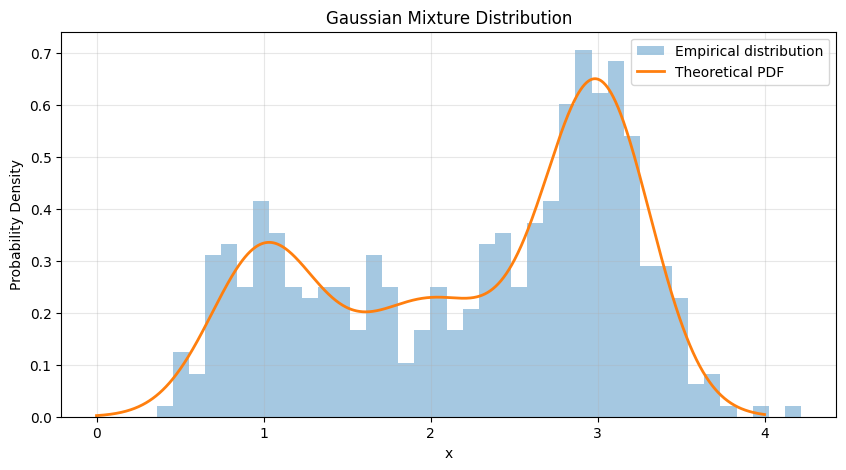

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Defining Mean & Standard Deviation Matrix
mu = [1.0, 3.0, 2.0]
sigma = [math.sqrt(0.1), math.sqrt(0.1), math.sqrt(0.2)]
np.random.seed(42)

# Creating 500 samples according to the rule:
samples = np.zeros(500)
for i in range(125):
  j = 4*i
  samples[j + 2] = norm.rvs(loc=mu[0], scale=sigma[0])
  samples[j] = norm.rvs(mu[1], sigma[1])
  samples[j + 1] = norm.rvs(mu[1], sigma[1])
  samples[j + 3] = norm.rvs(mu[2], sigma[2])

print(np.mean(samples))
print(np.std(samples))

# Plotting the GMM
x = np.linspace(0, 4, 1000)

pdf = (
    0.25 * norm.pdf(x, mu[0], sigma[0]) +
    0.50 * norm.pdf(x, mu[1], sigma[1]) +
    0.25 * norm.pdf(x, mu[2], sigma[2])
)

plt.figure(figsize=(10, 5))
plt.hist(samples, bins=40, density=True, alpha=0.4, label="Empirical distribution")
plt.plot(x, pdf, linewidth=2, label="Theoretical PDF")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.title("Gaussian Mixture Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 2. EM Algorithm

Σε κάθε επανάληψη (για $N$ δείγματα, $K$ συνιστώσες):

- **E-step:** υπολογίζουμε τα responsibilities $\gamma_{nk}=\dfrac{\pi_k\,\mathcal N(x_n|\mu_k,\sigma_k^2)}{\sum_j \pi_j\,\mathcal N(x_n|\mu_j,\sigma_j^2)}$.
- **M-step:** με $N_k=\sum_n\gamma_{nk}$ ενημερώνουμε $\pi_k=\dfrac{N_k}{N}$, $\mu_k=\dfrac{\sum_n\gamma_{nk}x_n}{N_k}$, $\sigma_k^2=\dfrac{\sum_n\gamma_{nk}(x_n-\mu_k)^2}{N_k}$.
- Το log-likelihood δεν μειώνεται σε καμία επανάληψη και το EM καταλήγει σε **τοπικό** μέγιστο. Γι' αυτό μας ενδιαφέρει πώς επηρεάζει η αρχικοποίηση το αποτέλεσμα.

### 2.1 Αρχικοποίηση παραμέτρων

| Μέθοδος | Μέσοι όροι | Διακυμάνσεις | Βάρη |
|---|---|---|---|
| `random_init` | τυχαίοι στο $[\min x,\max x]$ | τυχαίες στο $[0.01, 3]$ | Dirichlet |
| `random_samples_init` | $K$ τυχαία δείγματα | η συνολική διακύμανση των δεδομένων | ίσα ($1/K$) |
| `kmeans_init` | κέντρα K-means | διακύμανση κάθε cluster | ποσοστό δειγμάτων κάθε cluster |

In [ ]:
from sklearn.cluster import KMeans

K = 3
N = len(samples)
MAX_ITER = 500
TOL = 1e-6

# Ground truth (just for evaluation)
true_means = np.array([1.0, 3.0, 2.0])
true_vars = np.array([0.1, 0.1, 0.2])
true_weights = np.array([0.25, 0.50, 0.25])


def random_init():
    """Completely random initialization"""

    means = np.random.uniform(low=np.min(samples), high=np.max(samples), size=K)
    variances = np.random.uniform(0.01, 3.0, K)
    weights = np.random.dirichlet(np.ones(K))

    return means, variances, weights


def random_samples_init():
    """Select random observations as initial means"""

    indices = np.random.choice(N, K, replace=False)

    means = samples[indices]
    variances = np.full(K, np.var(samples))
    weights = np.ones(K) / K

    return means, variances, weights


def kmeans_init():
    """Initialize parameters using K-means"""

    X = samples.reshape(-1, 1)

    kmeans = KMeans(
        n_clusters=K,
        n_init=10,
        random_state=None
    )

    labels = kmeans.fit_predict(X)
    means = kmeans.cluster_centers_.flatten()
    weights = np.array([
        np.mean(labels == k) for k in range(K)
    ])

    variances = np.array([
        np.var(samples[labels == k])
        for k in range(K)
    ])

    return means, variances, weights

### 2.2 Log-likelihood και EM loop

- `log_likelihood`: υπολογίζει $\sum_n \ln\sum_k\pi_k\mathcal N(x_n|\mu_k,\sigma_k^2)$ με `logsumexp` για αριθμητική σταθερότητα.
- `EM`: εναλλάσσει E-step και M-step. Σταματά όταν η σχετική αλλαγή του log-likelihood γίνει μικρότερη από `TOL`, ή όταν φτάσει το `MAX_ITER`.


In [ ]:
from scipy.special import logsumexp

def log_likelihood(X, means, variances, weights):
    """Log-likelihood of the observation under the current GMM"""

    log_probs = (np.log(weights)[None, :] + norm.logpdf(X[:, None], loc=means[None, :], scale=np.sqrt(variances)[None, :]))

    return np.sum(logsumexp(log_probs, axis=1))


def EM(X, means, variances, weights, max_iter=MAX_ITER, tol=TOL):

    X = np.asarray(X)
    N = len(X)

    means = means.copy()
    variances = np.maximum(variances.copy(), 1e-6)
    weights = weights.copy()

    likelihood_history = []

    previous_ll = log_likelihood(X, means, variances, weights)

    likelihood_history.append(previous_ll)

    for iteration in range(max_iter):

        # =====================================
        # E-STEP: Calculate responsibilities
        # =====================================

        log_probs = (
            np.log(weights)[None, :]
            + norm.logpdf(
                X[:, None],
                loc=means[None, :],
                scale=np.sqrt(variances)[None, :]
            )
        )

        log_norm = logsumexp(log_probs, axis=1)

        responsibilities = np.exp(log_probs - log_norm[:, None])

        # =====================================
        # M-STEP: Update model parameters
        # =====================================

        Nk = np.sum(responsibilities, axis=0)

        weights = Nk / N

        means = (np.sum(responsibilities * X[:, None], axis=0) / Nk)

        variances = (np.sum(responsibilities * (X[:, None] - means)**2, axis=0) / Nk)

        # Avoid numerical variance collapse
        variances = np.maximum(variances, 1e-6)

        # =====================================
        # Check convergence
        # =====================================

        current_ll = log_likelihood(X, means, variances, weights)

        likelihood_history.append(current_ll)

        if abs(current_ll - previous_ll) < tol * (1 + abs(previous_ll)):
            break

        previous_ll = current_ll

    return {
        "means": means,
        "variances": variances,
        "weights": weights,
        "iterations": iteration + 1,
        "log_likelihood": likelihood_history[-1],
        "likelihood_history": likelihood_history
    }


## 3. Trials

Κάθε αρχικοποίηση τρέχει `NUM_TRIALS = 30` φορές. Όλα τα αποτελέσματα αποθηκεύονται στο `results`.

In [ ]:
initializers = {
    "Random": random_init,
    "Random samples": random_samples_init,
    "K-means": kmeans_init
}

NUM_TRIALS = 30

results = {}

for name, initializer in initializers.items():

    results[name] = []

    for trial in range(NUM_TRIALS):

        means, variances, weights = initializer()

        result = EM(
            samples,
            means,
            variances,
            weights
        )

        results[name].append(result)

## 4. Αξιολόγηση

### 4.1 Μετρικές σφάλματος

Η σειρά των συνιστωσών στο EM είναι αυθαίρετη (label switching). Γι' αυτό ταξινομούμε τις εκτιμήσεις και τις αληθινές τιμές με βάση τον μέσο όρο πριν συγκριθούν. Υπολογίζεται το MSE για τους μέσους, τις διακυμάνσεις και τα βάρη, και το άθροισμά τους (Total MSE).

In [ ]:
# Sort ground truth by mean
true_order = np.argsort(true_means)

sorted_true_means = true_means[true_order]
sorted_true_vars = true_vars[true_order]
sorted_true_weights = true_weights[true_order]


def calculate_errors(result):

    order = np.argsort(result["means"])

    estimated_means = result["means"][order]
    estimated_vars = result["variances"][order]
    estimated_weights = result["weights"][order]

    mean_error = np.mean(
        (estimated_means - sorted_true_means)**2
    )

    variance_error = np.mean(
        (estimated_vars - sorted_true_vars)**2
    )

    weight_error = np.mean(
        (estimated_weights - sorted_true_weights)**2
    )

    total_error = mean_error + variance_error + weight_error

    return mean_error, variance_error, weight_error, total_error


### 4.2 Mean και Variance σε 30 trials

In [ ]:
import pandas as pd

summary_data = []

for name, trials in results.items():

    for result in trials:

        mean_err, var_err, weight_err, total_err = (
            calculate_errors(result)
        )

        summary_data.append({
            "Initialization": name,
            "Iterations": result["iterations"],
            "Log-likelihood": result["log_likelihood"],
            "Mean MSE": mean_err,
            "Variance MSE": var_err,
            "Weight MSE": weight_err,
            "Total MSE": total_err,
            "Converged": result["iterations"] < MAX_ITER
        })

df = pd.DataFrame(summary_data)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print(df.groupby("Initialization").agg({
    "Iterations": ["mean", "std"],
    "Log-likelihood": ["mean", "std"],
    "Mean MSE": ["mean", "std"],
    "Variance MSE": ["mean", "std"],
    "Weight MSE": ["mean", "std"],
    "Total MSE": ["mean", "std"],
    "Converged": "mean"
}).round(6))


                Iterations            Log-likelihood            Mean MSE           Variance MSE           Weight MSE           Total MSE           Converged
                      mean        std           mean       std      mean       std         mean       std       mean       std      mean       std      mean
Initialization                                                                                                                                              
K-means         118.933333   0.253708    -555.975673  0.000041  0.026946  0.000011     0.001259  0.000000   0.002302  0.000001  0.030507  0.000012       1.0
Random          113.933333  48.883347    -555.664350  0.190544  0.020190  0.005683     0.017330  0.009891   0.010849  0.005211  0.048369  0.010445       1.0
Random samples   82.000000  23.009743    -555.607045  0.145763  0.019264  0.005004     0.020107  0.007599   0.012376  0.003986  0.051747  0.007430       1.0


**Παρατηρούμε ότι:**
- Όλες οι εκτελέσεις συγκλίνουν (`Converged = 1.0`).
- **K-means:** σχεδόν μηδενική διασπορά (≈119 επαναλήψεις, std του log-likelihood ≈ 4·10⁻⁵). Καταλήγει κάθε φορά στο ίδιο τοπικό βέλτιστο.
- **Random / Random samples:** μεγαλύτερη διασπορά στις επαναλήψεις (Random: ≈114 ± 49, Random samples: ≈82 ± 23) και ελαφρώς υψηλότερο μέσο log-likelihood (≈ −555.6 έναντι −556.0).
- Όμως το σφάλμα ως προς τις αληθινές παραμέτρους είναι **μικρότερο στο K-means** (Total MSE ≈ 0.031 έναντι ≈ 0.048–0.052). Υψηλότερο log-likelihood δεν σημαίνει πιο κοντά στις αληθινές τιμές: το EM μεγιστοποιεί την πιθανοφάνεια του συγκεκριμένου δείγματος των 500 σημείων.

### 4.3 Καλύτερη εκτέλεση ανά μέθοδο (σύμφωνα με το log-likelihood)

In [ ]:
import numpy as np

np.set_printoptions(precision=4, suppress=True)

for name, trials in results.items():
    best_trial = max(trials, key=lambda r: r["log_likelihood"])

    print(rf"=== {name} ===")
    print(rf"   Means:      {best_trial['means']}")
    print(rf"   Variances:  {best_trial['variances']}")
    print(rf"   Weights:    {best_trial['weights']}")
    print("-" * 50)

=== Random ===
   Means:      [0.9852 2.2261 3.0313]
   Variances:  [0.0738 0.4592 0.073 ]
   Weights:    [0.2213 0.4054 0.3732]
--------------------------------------------------
=== Random samples ===
   Means:      [2.2189 0.9836 3.0306]
   Variances:  [0.4606 0.0732 0.0735]
   Weights:    [0.4047 0.2199 0.3754]
--------------------------------------------------
=== K-means ===
   Means:      [2.9579 0.9202 1.7303]
   Variances:  [0.1225 0.0541 0.2341]
   Weights:    [0.5463 0.1839 0.2698]
--------------------------------------------------


**Παρατηρούμε ότι:**
- Οι δείκτες των συνιστωσών δεν αντιστοιχούν μεταξύ των μεθόδων, οπότε συγκρινουμε τις τιμές και όχι μία προς μία τις θέσεις.
- Οι **Random** και **Random samples** καταλήγουν σχεδόν στην ίδια λύση (βλ. means) με μια μεγάλη διακύμανση στη μία συνιστώσα, το οποίο είναι εμφανώς λάθος.
- H **K-means** έχει διακυμάνσεις πιο κοντά στις αληθινές (0.1, 0.2, 0.1). Αυτό εξηγεί το μικρότερο MSE, παρότι το log-likelihood είναι ελάχιστα χαμηλότερο.
- Η εκτίμηση δεν ανακτά ακριβώς τις αληθινές τιμές, αλλά αυτό ίσως οφείλεται και στο μικρό δείγμα.

## 5. Γραφική απεικόνιση αποτελεσμάτων

### 5.1 Σύγκριση μετρικών ανά αρχικοποίηση

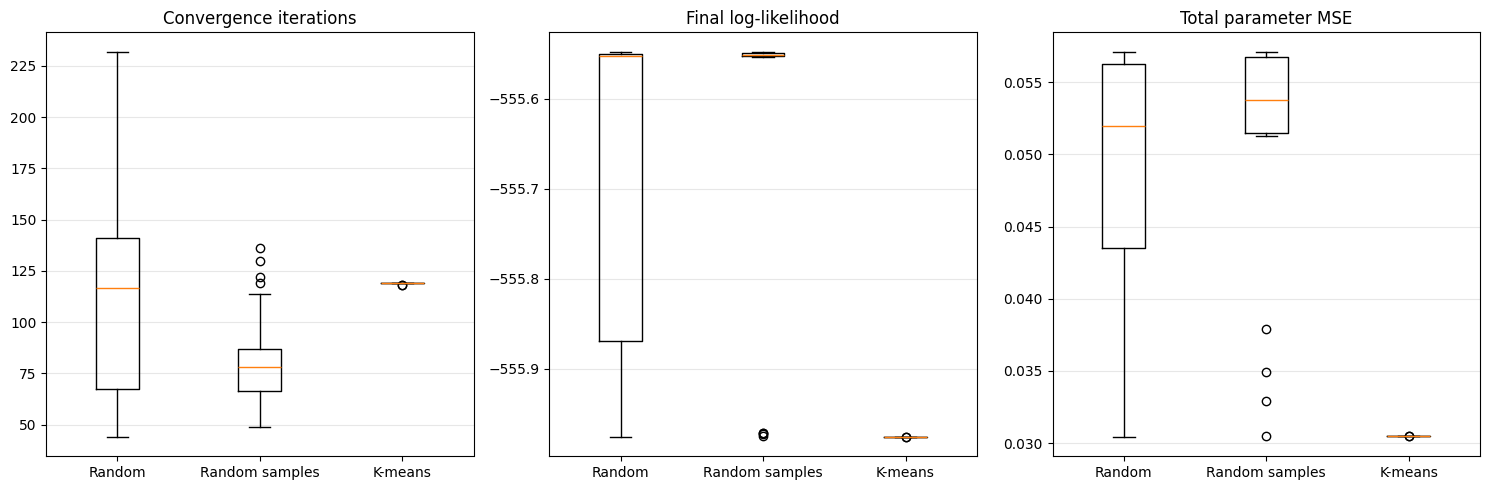

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ("Iterations", "Convergence iterations"),
    ("Log-likelihood", "Final log-likelihood"),
    ("Total MSE", "Total parameter MSE")
]

for ax, (metric, title) in zip(axes, metrics):

    data = [
        df[df["Initialization"] == name][metric].values
        for name in initializers
    ]

    ax.boxplot(data, tick_labels=list(initializers.keys()))
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Παρατηρούμε ότι:**
- **Επαναλήψεις:** Η Random έχει τη μεγαλύτερη διασπορά, η Random samples συγκλίνει συνήθως πιο γρήγορα και η K-means είναι πιο σταθερή.
- **Log-likelihood:** εμφανίζονται δύο τοπικά βέλτιστα, −555.55 και −555.97. Η K-means καταλήγει πάντα στο δεύτερο.
- **MSE:** το βέλτιστο με το χαμηλότερο log-likelihood (K-means) έχει το μικρότερο σφάλμα. Οι λίγες εκτελέσεις Random με χαμηλό MSE είναι αυτές που έπεσαν στο ίδιο βέλτιστο.

### 5.2 Estimated pdf VS original

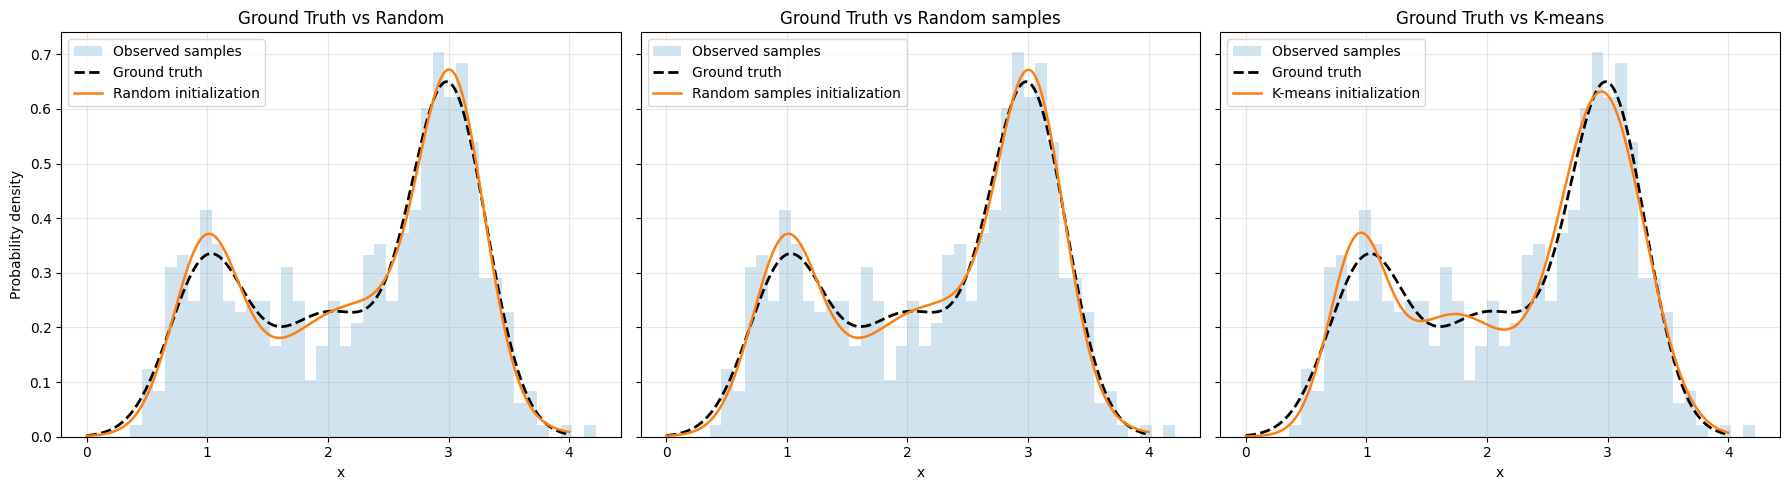

In [ ]:
x = np.linspace(0, 4, 1000)

true_pdf = sum(true_weights[k] * norm.pdf(x, true_means[k], np.sqrt(true_vars[k])) for k in range(K))
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, (name, trials) in enumerate(results.items()):
    ax = axes[i]

    ax.hist(
        samples, bins=40, density=True,
        alpha=0.2, label="Observed samples"
    )

    ax.plot(x, true_pdf, "k--", linewidth=2, label="Ground truth")

    best = max(trials, key=lambda r: r["log_likelihood"])

    estimated_pdf = sum(
        best["weights"][k] * norm.pdf(
            x,
            best["means"][k],
            np.sqrt(best["variances"][k])
        )
        for k in range(K)
    )

    ax.plot(
        x, estimated_pdf, linewidth=1.8,
        label=f"{name} initialization"
    )

    ax.set_title(f"Ground Truth vs {name}")
    ax.set_xlabel("x")
    if i == 0:
        ax.set_ylabel("Probability density")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3  Log-likelihood plots

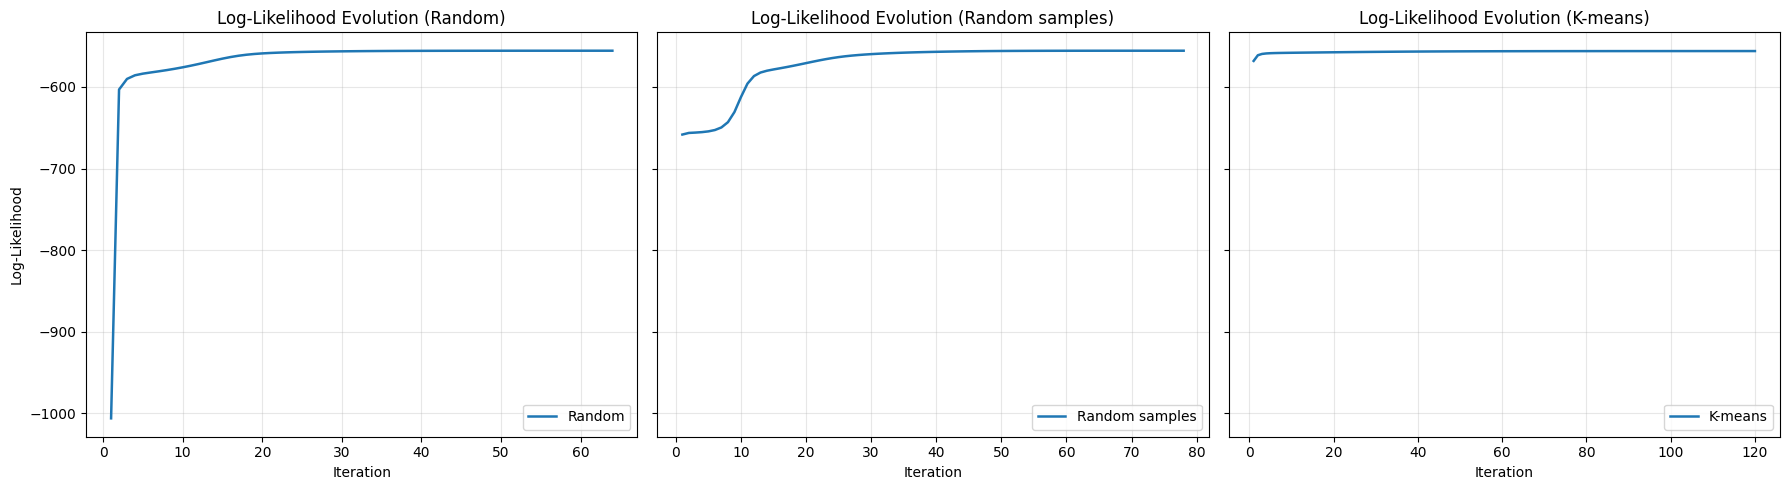

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, (name, trials) in enumerate(results.items()):
    ax = axes[i]

    best = max(trials, key=lambda r: r["log_likelihood"])

    likelihood_history = best["likelihood_history"]

    ax.plot(
        range(1, len(likelihood_history) + 1),
        likelihood_history,
        linewidth=1.8,
        color="tab:blue",
        label=f"{name}"
    )

    ax.set_title(f"Log-Likelihood Evolution ({name})")
    ax.set_xlabel("Iteration")
    if i == 0:
        ax.set_ylabel("Log-Likelihood")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Παρατηρούμε ότι:**
- Σε όλες τις περιπτώσεις το log-likelihood αυξάνεται μονότονα.
- **Random:** ξεκινά πολύ χαμηλά και ανεβαίνει απότομα στις πρώτες επαναλήψεις.
- **Random samples:** ξεκινά από αρκετά υψηλότερα και έχει σταθεροποιείται σχετικά σύντομα μετά από λιγές επαναλήψεις.
- **K-means:** ξεκινά ήδη κοντά στο τελικό επίπεδο και ουσιαστικά στις επαναλήψεις γίνονται πολλές μικρές βελτιώσεις έως την τελική σύγκλιση.

## 6. Συμπεράσματα

- Το EM εξαρτάται από την αρχικοποίηση, επειδή συγκλίνει σε **τοπικά** βέλτιστα.
- **K-means:** σταθερό και επαναλήψιμο αποτέλεσμα, με την πιο κοντινή στις αληθινές παραμέτρους λύση. Συγκλίνει όμως πιο αργά.
- **Random / Random samples:** ταχύτερα, αλλά με μεγαλύτερη διασπορά.
- Στην πράξη μπορεί κανείς να κάνει πολλαπλές επανεκκινήσεις και επιλογή της καλύτερης με βάση το log-likelihood (όπως στο 4.3), ή αρχικοποίηση με K-means.

Όπως αναφέρεται και στο βιβλιο του Bishop, "It is common to run the K-means algorithm in order to find a suitable initialization for a Gaussian mixture model that is subsequently adapted using EM".